<a href="https://colab.research.google.com/github/JantikarShobith/BIS_LAB/blob/main/1BM24CS351_Week7_GEA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Evolving Solar PV Power Forecasting Equation via GEP...

Gen   1 | Best RMSE: 18.193 MW | Formula: T
Gen  50 | Best RMSE:  1.514 MW | Formula: (50.0 * G)


/tmp/ipykernel_1618/3162079840.py:29: RuntimeWarning: divide by zero encountered in divide
  "/": (2, lambda a, b: np.where(np.abs(b) > 1e-6, a / b, 1.0))  # Protected division


Gen 100 | Best RMSE:  1.514 MW | Formula: (50.0 * G)
Gen 150 | Best RMSE:  1.514 MW | Formula: (50.0 * G)
Gen 200 | Best RMSE:  1.514 MW | Formula: (50.0 * G)
Gen 250 | Best RMSE:  1.514 MW | Formula: (50.0 * G)

          GENE EXPRESSION PROGRAMMING (GEP) SOLAR MODEL RESULTS          
 Karva Chromosome (Genotype) : * 50.0 G 0.05 G G 50.0 0.05 1.0 W G G 50.0 G 0.2 T 0.2
 Active Coding Length        : 3 / 17 symbols
 Discovered Formula          : P_solar = (50.0 * G)
-------------------------------------------------------------------------
 Prediction RMSE             : 1.5136 MW (on a 50 MW solar plant)
 Goodness of Fit (R² Score)  : 0.98813


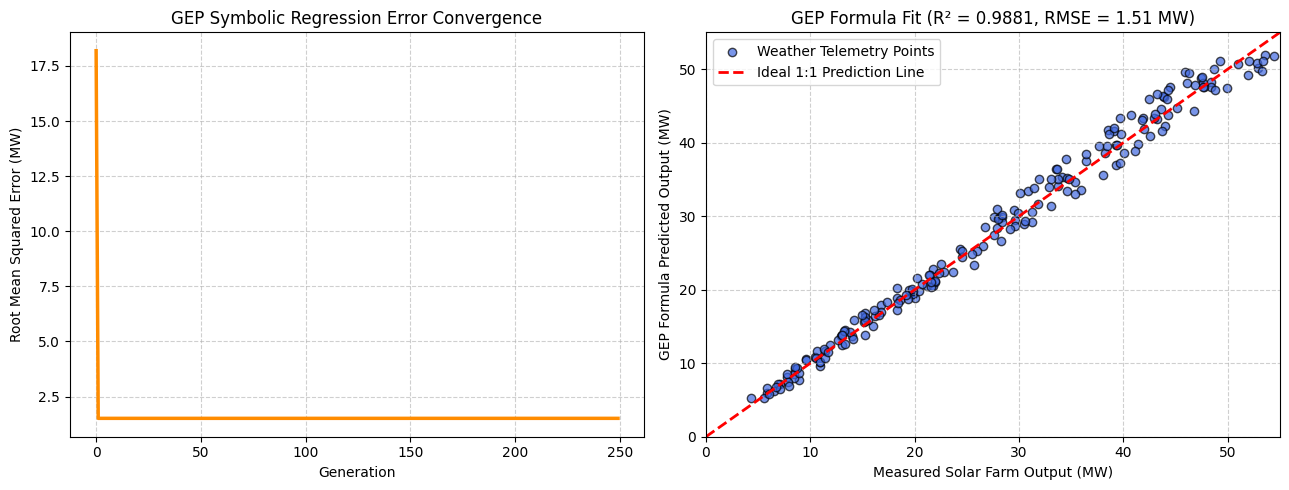

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

# =========================================================
# 1. SOLAR FARM TELEMETRY DATASET GENERATION (200 READINGS)
# =========================================================
np.random.seed(42)
NUM_SAMPLES = 200

# Weather sensor inputs
G = np.random.uniform(0.10, 1.05, NUM_SAMPLES)   # Solar Irradiance (kW/m^2)
T = np.random.uniform(10.0, 45.0, NUM_SAMPLES)   # Ambient Temperature (°C)
W = np.random.uniform(0.50, 12.0, NUM_SAMPLES)   # Wind Speed (m/s)

# True physical PV output (MW) with thermal derating + wind cooling + sensor noise
P_clean = 50.0 * G * (1.0 - 0.0045 * (T - 25.0 + 3.0 * G - 0.4 * W))
P_measured = P_clean + np.random.normal(0.0, 0.35, NUM_SAMPLES)  # +/- 0.35 MW sensor noise

DATASET = {"G": G, "T": T, "W": W}

# =========================================================
# 2. GEP SYMBOL SETS & HEAD-TAIL ARCHITECTURE
# =========================================================
FUNCTIONS = {
    "+": (2, lambda a, b: a + b),
    "-": (2, lambda a, b: a - b),
    "*": (2, lambda a, b: a * b),
    "/": (2, lambda a, b: np.where(np.abs(b) > 1e-6, a / b, 1.0))  # Protected division
}

# Terminals: Weather features + useful physical scaling constants
CONSTANTS = {"50.0": 50.0, "1.0": 1.0, "0.2": 0.2, "0.05": 0.05}
TERMINALS = list(DATASET.keys()) + list(CONSTANTS.keys())
ALL_SYMBOLS = list(FUNCTIONS.keys()) + TERMINALS

HEAD_LEN = 8
MAX_ARITY = 2
TAIL_LEN = HEAD_LEN * (MAX_ARITY - 1) + 1  # Structural guarantee: t = h*(n_max - 1) + 1 = 9
GENE_LEN = HEAD_LEN + TAIL_LEN             # Total fixed chromosome length = 17

# GEP Evolutionary Hyperparameters
POP_SIZE = 150
MAX_GENERATIONS = 250
P_MUTATION = 0.08
P_CROSSOVER = 0.70
P_TRANSPOSITION = 0.15
PARSIMONY_WEIGHT = 0.015  # Slight penalty for overly long formulas

# =========================================================
# 3. KARVA DECODING (GENOTYPE -> EXPRESSION TREE -> FORMULA)
# =========================================================
class Node:
    def __init__(self, symbol):
        self.symbol = symbol
        self.children = []

def decode_karva_tree(chromosome):
    """Decodes a linear Karva string breadth-first into an Expression Tree."""
    root = Node(chromosome[0])
    queue = deque([root])
    idx = 1

    while queue and idx < len(chromosome):
        current = queue.popleft()
        if current.symbol in FUNCTIONS:
            arity, _ = FUNCTIONS[current.symbol]
            for _ in range(arity):
                if idx < len(chromosome):
                    child = Node(chromosome[idx])
                    current.children.append(child)
                    queue.append(child)
                    idx += 1
    return root, idx  # idx equals exact number of active coding symbols

def evaluate_tree(node, data):
    """Vectorized evaluation of Expression Tree across all weather samples."""
    if node.symbol in FUNCTIONS:
        _, func = FUNCTIONS[node.symbol]
        args = [evaluate_tree(child, data) for child in node.children]
        return func(*args)
    elif node.symbol in data:
        return data[node.symbol]
    else:
        return np.full(NUM_SAMPLES, CONSTANTS[node.symbol])

def tree_to_infix(node):
    """Converts an Expression Tree into a clean, human-readable algebraic equation."""
    if node.symbol in FUNCTIONS:
        left = tree_to_infix(node.children[0])
        right = tree_to_infix(node.children[1])
        return f"({left} {node.symbol} {right})"
    return node.symbol

# =========================================================
# 4. FITNESS EVALUATION & GENETIC OPERATORS
# =========================================================
def evaluate_chromosome(chromosome):
    tree, active_len = decode_karva_tree(chromosome)
    preds = evaluate_tree(tree, DATASET)

    # Guard against numerical overflow
    if np.any(np.isnan(preds)) or np.any(np.isinf(preds)):
        return 0.0, float("inf"), active_len

    rmse = np.sqrt(np.mean((P_measured - preds) ** 2))
    fitness = 1000.0 / (1.0 + rmse + PARSIMONY_WEIGHT * active_len)
    return fitness, rmse, active_len

def random_chromosome():
    head = [np.random.choice(ALL_SYMBOLS) for _ in range(HEAD_LEN)]
    tail = [np.random.choice(TERMINALS) for _ in range(TAIL_LEN)]
    return head + tail

def mutate(chrom):
    child = chrom.copy()
    for i in range(GENE_LEN):
        if np.random.rand() < P_MUTATION:
            if i < HEAD_LEN:
                child[i] = np.random.choice(ALL_SYMBOLS)
            else:
                child[i] = np.random.choice(TERMINALS)
    return child

def crossover(p1, p2):
    if np.random.rand() > P_CROSSOVER:
        return p1.copy(), p2.copy()
    pt = np.random.randint(1, GENE_LEN - 1)
    return p1[:pt] + p2[pt:], p2[:pt] + p1[pt:]

def transpose(chrom):
    """Insertion Sequence (IS) transposition: copies a short block into the head."""
    if np.random.rand() > P_TRANSPOSITION:
        return chrom
    child = chrom.copy()
    seq_len = np.random.randint(1, 4)
    start = np.random.randint(0, GENE_LEN - seq_len)
    target = np.random.randint(1, HEAD_LEN)  # Keep root at index 0 intact
    seq = child[start:start + seq_len]

    # Insert sequence into head while preserving head length
    new_head = (child[:target] + seq + child[target:HEAD_LEN])[:HEAD_LEN]
    return new_head + child[HEAD_LEN:]

# =========================================================
# 5. MAIN GENE EXPRESSION PROGRAMMING EVOLUTION LOOP
# =========================================================
def run_gep_solar_forecasting():
    population = [random_chromosome() for _ in range(POP_SIZE)]
    best_chrom = None
    best_rmse = float("inf")
    best_fitness = -1.0
    rmse_history = []

    print("Evolving Solar PV Power Forecasting Equation via GEP...\n")

    for gen in range(MAX_GENERATIONS):
        evaluated = [evaluate_chromosome(c) for c in population]
        fitnesses = np.array([e[0] for e in evaluated])
        rmses = np.array([e[1] for e in evaluated])

        gen_best_idx = np.argmax(fitnesses)
        if fitnesses[gen_best_idx] > best_fitness:
            best_fitness = fitnesses[gen_best_idx]
            best_rmse = rmses[gen_best_idx]
            best_chrom = population[gen_best_idx].copy()

        rmse_history.append(best_rmse)

        if (gen + 1) % 50 == 0 or gen == 0:
            tree, _ = decode_karva_tree(best_chrom)
            print(f"Gen {gen+1:3d} | Best RMSE: {best_rmse:6.3f} MW | Formula: {tree_to_infix(tree)}")

        # Elitism: carry top 2 formulas forward unchanged
        elite_indices = np.argsort(fitnesses)[-2:]
        next_pop = [population[idx].copy() for idx in elite_indices]

        # Tournament Selection + Variation
        while len(next_pop) < POP_SIZE:
            t1 = np.random.choice(POP_SIZE, size=4, replace=False)
            t2 = np.random.choice(POP_SIZE, size=4, replace=False)
            p1 = population[t1[np.argmax(fitnesses[t1])]]
            p2 = population[t2[np.argmax(fitnesses[t2])]]

            c1, c2 = crossover(p1, p2)
            c1 = transpose(mutate(c1))
            c2 = transpose(mutate(c2))

            next_pop.append(c1)
            if len(next_pop) < POP_SIZE:
                next_pop.append(c2)

        population = next_pop

    return best_chrom, best_rmse, rmse_history

# =========================================================
# 6. EXECUTION, EQUATION EXTRACTION & VISUALIZATION
# =========================================================
best_gene, final_rmse, history = run_gep_solar_forecasting()
best_tree, active_symbols = decode_karva_tree(best_gene)
discovered_formula = tree_to_infix(best_tree)
predicted_power = evaluate_tree(best_tree, DATASET)

# Compute R^2 Score
ss_res = np.sum((P_measured - predicted_power) ** 2)
ss_tot = np.sum((P_measured - np.mean(P_measured)) ** 2)
r2_score = 1.0 - (ss_res / ss_tot)

print("\n=========================================================================")
print("          GENE EXPRESSION PROGRAMMING (GEP) SOLAR MODEL RESULTS          ")
print("=========================================================================")
print(f" Karva Chromosome (Genotype) : {' '.join(best_gene)}")
print(f" Active Coding Length        : {active_symbols} / {GENE_LEN} symbols")
print(f" Discovered Formula          : P_solar = {discovered_formula}")
print("-------------------------------------------------------------------------")
print(f" Prediction RMSE             : {final_rmse:.4f} MW (on a 50 MW solar plant)")
print(f" Goodness of Fit (R² Score)  : {r2_score:.5f}")
print("=========================================================================")

# Visualization: Evolution Convergence & Predicted vs. Measured PV Output
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left Plot: RMSE Reduction across Generations
ax1.plot(history, color='darkorange', linewidth=2.5)
ax1.set_title("GEP Symbolic Regression Error Convergence")
ax1.set_xlabel("Generation")
ax1.set_ylabel("Root Mean Squared Error (MW)")
ax1.grid(True, linestyle='--', alpha=0.6)

# Right Plot: Actual vs GEP Formula Predicted Solar Output
ax2.scatter(P_measured, predicted_power, color='royalblue', alpha=0.7, edgecolors='black', label='Weather Telemetry Points')
lims = [0, 55]
ax2.plot(lims, lims, 'r--', linewidth=2, label='Ideal 1:1 Prediction Line')
ax2.set_xlim(lims)
ax2.set_ylim(lims)
ax2.set_xlabel("Measured Solar Farm Output (MW)")
ax2.set_ylabel("GEP Formula Predicted Output (MW)")
ax2.set_title(f"GEP Formula Fit (R² = {r2_score:.4f}, RMSE = {final_rmse:.2f} MW)")
ax2.legend(loc='upper left')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()
